# Dataset and Initial Audit: Figures for Section 3.2

This notebook reproduces the descriptive statistics and figures for Sections 3.2.2–3.2.8 from `outputs/prepared/manifest.jsonl`. All values are computed from the audited dataset. The figures describe this observed collection only; they do not estimate the composition of the wider Vietnamese e-commerce market.

Generated figures are saved as both PNG (300 dpi) and SVG under `outputs/figures/dataset_audit/`.

## Tái lập kết quả: tệp cần thiết, quy trình và cách đọc hình

### Phạm vi và dữ liệu đầu vào

Notebook này tạo lại các thống kê và hình cho Mục 3.2. Nó chỉ đọc hai tệp dữ liệu đã chuẩn bị là `outputs/prepared/manifest.jsonl` và `outputs/prepared/audit.json`; các hình và CSV được tạo lại từ hai tệp đó. Để tái tạo từ dữ liệu thô, cần có các tệp sau:

| Tệp/thư mục | Bắt buộc? | Đặc điểm và mục đích | Đóng góp vào nghiên cứu |
|---|---|---|---|
| `data/fashion_raw.xlsx` | Có khi chạy lại bước chuẩn bị | Bảng Excel nguồn; sheet được chọn mặc định là sheet đầu tiên. Cần có các cột `product_id`, `product`, `img_local_path`. | Cung cấp mã sản phẩm, tiêu đề gốc và đường dẫn ảnh; là cơ sở xác định phạm vi mẫu nghiên cứu. |
| `data/shopee_img/` | Có khi chạy lại bước chuẩn bị | Thư mục ảnh cục bộ. Đường dẫn tương đối trong `img_local_path` được nối với thư mục này; ảnh đọc được sẽ có kích thước, SHA-256 và dHash được ghi nhận. | Cho phép kiểm tra ảnh có tồn tại/đọc được và mô tả thuộc tính tệp ảnh; không tự xác nhận ảnh có đúng sản phẩm hay không. |
| `fashion_vn/prepare.py` và `fashion_vn/text.py` | Có khi tái tạo manifest | Mã kiểm tra Excel/ảnh, chuẩn hóa tiêu đề, trích nhãn yếu, gợi ý loại sản phẩm, nhận diện trùng và chia nhóm. Quy tắc từ vựng/chuẩn hóa nằm trong `text.py`. | Định nghĩa chính xác phép biến đổi dữ liệu; nhãn loại và thuộc tính từ tiêu đề là nhãn yếu, không phải ground truth. |
| `requirements-lock.txt` | Khuyến nghị mạnh | Khóa phiên bản các thư viện Python để hạn chế khác biệt môi trường; `requirements.txt` chỉ quy định các khoảng phiên bản rộng hơn. | Giúp chạy lại cùng bộ thư viện. Cần ghi thêm phiên bản Python, hệ điều hành và thay đổi mã nếu báo cáo mức tái lập chặt chẽ. |
| `outputs/prepared/manifest.jsonl` | Có cho notebook này | JSON Lines, mỗi dòng là một sản phẩm với tiêu đề thô/chuẩn hóa, đường dẫn và trạng thái ảnh, kích thước, hash, loại gợi ý, thuộc tính tiêu đề, cờ chất lượng, nhóm trùng và split. | Là nguồn dữ liệu cấp bản ghi cho mọi thống kê và biểu đồ. Đây là tệp trung gian quan trọng nhất cần lưu cùng kết quả. |
| `outputs/prepared/audit.json` | Có cho notebook này | JSON tổng hợp số sản phẩm, trạng thái ảnh, phân loại gợi ý, split, cờ, độ phủ nhãn yếu, seed, chính sách chia và giới hạn. | Lưu lại bối cảnh/kiểm tra của lần chuẩn bị; notebook đọc tệp này để giữ hồ sơ kiểm toán cùng manifest. |

### Tạo lại đầu vào và chạy notebook

Chạy từ thư mục gốc dự án trong PowerShell, dùng đúng môi trường và seed đã công bố. Không sửa thủ công manifest giữa bước chuẩn bị và bước vẽ hình.

```powershell
.\.venv\Scripts\python.exe -m pip install -r requirements-lock.txt
.\.venv\Scripts\python.exe -m fashion_vn.prepare --xlsx data/fashion_raw.xlsx --image-root data --out outputs/prepared --seed 42
```

Sau đó mở và chạy toàn bộ notebook theo thứ tự từ trên xuống. Notebook tự dò thư mục gốc để tìm manifest và lưu kết quả vào `outputs/figures/dataset_audit/`. Lệnh chuẩn bị tạo lại cả `manifest.jsonl`, `audit.json` và các tệp hỗ trợ. Seed 42 cố định cách chia nhóm; các nhóm nối bởi tiêu đề chuẩn hóa, SHA-256 hoặc dHash chính xác được giữ trong cùng split train/val/test theo tỷ lệ xấp xỉ 80/10/10. Nếu đổi dữ liệu, từ điển trong `text.py`, seed hoặc mã, cần coi đó là một phiên bản thí nghiệm mới và lưu lại các thay đổi.

### Tệp tạo sinh và tệp tùy chọn

| Tệp | Vai trò | Có cần để tạo các hình trong notebook? |
|---|---|---|
| `outputs/prepared/title_weak_labels.xlsx` | Bảng tiện kiểm tra nhãn yếu theo từng sản phẩm; nhãn trích từ tiêu đề và loại sản phẩm đều chưa được xác minh thủ công. | Không; được tạo cùng lúc với manifest nhưng notebook không đọc. |
| `outputs/prepared/vocabulary_review.csv` | Danh sách token trong train để rà soát từ vựng; hữu ích cho pipeline học mô hình. | Không. |
| `outputs/prepared/annotation_blind.csv`, `annotation_gallery.html`, `gold_long_template.csv` | Phiếu và gallery hỗ trợ gán nhãn độc lập; mẫu bỏ tiêu đề và dự đoán máy để giảm thiên lệch. | Không; chỉ cần cho đánh giá thủ công/ground truth về sau. |
| `outputs/prepared/dataset_profile.json`, `DATA_REPORT.md` | Báo cáo kiểm kê bổ sung nếu có trong lần chuẩn bị/kiểm toán. | Không; không được notebook này đọc. |
| `outputs/figures/dataset_audit/figure_*.png` và `figure_*.svg` | Hình xuất ra; PNG 300 dpi thuận tiện chèn vào luận văn, SVG phù hợp chỉnh sửa/in ấn không vỡ nét. | Đây là đầu ra, không phải đầu vào. Được tạo lại khi chạy notebook. |
| `outputs/figures/dataset_audit/3_2_*.csv` | Bảng số liệu hỗ trợ tương ứng cho tóm tắt, nhóm loại, nhóm thuộc tính, cờ và chỉ báo trùng. | Đây là đầu ra phục vụ kiểm tra/trích số liệu, không phải đầu vào. |

### Ý nghĩa các hình trong Mục 3.2

| Hình | Nội dung và cách đọc | Ý nghĩa/giới hạn khi viết luận văn |
|---|---|---|
| Figure 3.2.2, `figure_3_2_2_dataset_summary` | Thanh ngang so sánh số ảnh đọc được, nội dung ảnh SHA-256 phân biệt, tiêu đề thô/chuẩn hóa duy nhất, nhóm trùng liên thông và sản phẩm có ít nhất một nhóm thuộc tính từ tiêu đề. | Tóm tắt mức sẵn có, duy nhất và độ phủ nhãn yếu. Các đại lượng lồng lấp/khác định nghĩa, không cộng thành tổng. |
| Figure 3.2.3, `figure_3_2_3_title_characteristics` | Histogram số token tách bằng khoảng trắng trong tiêu đề chuẩn hóa và boxplot độ dài theo token/ký tự; có đánh dấu trung bình và trung vị. | Cho thấy độ dài và độ phân tán tiêu đề. Token ở đây không phải đơn vị từ vựng tiếng Việt đã phân đoạn ngôn ngữ học. |
| Figure 3.2.4, `figure_3_2_4_image_characteristics` | Top kích thước ảnh và các chỉ báo ảnh đọc được, ảnh vuông, ảnh 320×320 và cạnh ngắn tối thiểu 224 px. | Mô tả đặc điểm tệp và mức phù hợp kích thước đầu vào; không đo chất lượng ngữ nghĩa, ảnh ghép, watermark hay việc ảnh có đúng sản phẩm. |
| Figure 3.2.5, `figure_3_2_5_title_inferred_composition` | Số bản ghi theo loại sản phẩm do quy tắc có thứ tự trên tiêu đề gợi ý. | Mô tả cơ cấu phân loại của chính mẫu này, không phải thị phần Shopee/toàn thị trường; nhãn chưa được xác minh thủ công. |
| Figure 3.2.6, `figure_3_2_6_weak_attribute_coverage` | Số sản phẩm có ít nhất một giá trị từ điển trong từng nhóm thuộc tính; nhóm chất liệu được tô riêng. | Đánh giá độ phủ nhãn yếu để nhận diện nhóm có thể phân tích. Một sản phẩm có thể thuộc nhiều nhóm; chất liệu là lời khai tiêu đề/người bán, không được ảnh xác thực. |
| Figure 3.2.7, `figure_3_2_7_noise_flags` | Số lần xuất hiện của từng cờ chất lượng/nhiễu trong tiêu đề và bản ghi. | Cho thấy các vấn đề cần thận trọng khi huấn luyện/diễn giải. Cờ không loại trừ lẫn nhau và là luật phát hiện bảo thủ, không bao quát mọi lỗi. |
| Figure 3.2.8, `figure_3_2_8_duplicate_analysis` | Hai panel: số giá trị/nhóm duy nhất theo từng chỉ báo trùng và phần giảm so với tổng số bản ghi; notebook cũng đếm nhóm liên thông xuất hiện ở nhiều split. | Giải thích cách giảm rò rỉ giữa train/validation/test. dHash ở đây chỉ so khớp chính xác, có thể bỏ sót ảnh gần trùng hoặc gom nhầm; không chứng minh đã loại mọi phụ thuộc sản phẩm/shop. |

Hãy diễn giải các tỷ lệ như mô tả bộ dữ liệu đã kiểm toán, không suy rộng thành ước lượng thị trường. Các nhãn từ tiêu đề là tín hiệu yếu; thuộc tính không được nhắc đến là *chưa biết*, không phải *không có*. Mỗi hình được lưu đồng thời PNG và SVG; CSV hỗ trợ có cùng số đếm để đối chiếu khi viết bảng/kết quả.

In [1]:
import importlib.util

required = ['numpy', 'pandas', 'matplotlib', 'PIL']
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError(
        f'Missing notebook dependencies: {missing}. Install requirements-lock.txt before execution.'
    )
print('Notebook dependencies are available.')

Notebook dependencies are available.


In [2]:
from pathlib import Path
import json
import collections
import statistics
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Locate the project root whether the notebook is launched from the root or notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'outputs' / 'prepared' / 'manifest.jsonl').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
MANIFEST = PROJECT_ROOT / 'outputs' / 'prepared' / 'manifest.jsonl'
AUDIT = PROJECT_ROOT / 'outputs' / 'prepared' / 'audit.json'
FIGURE_DIR = PROJECT_ROOT / 'outputs' / 'figures' / 'dataset_audit'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

records = [json.loads(line) for line in MANIFEST.read_text(encoding='utf-8').splitlines() if line.strip()]
audit = json.loads(AUDIT.read_text(encoding='utf-8'))
N = len(records)

plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300, 'font.size': 10,
    'axes.titlesize': 12, 'axes.labelsize': 10,
    'figure.facecolor': 'white', 'axes.facecolor': 'white'
})
COLORS = {'primary': '#2457A6', 'secondary': '#59A14F', 'accent': '#E17C05',
          'warning': '#C94C4C', 'neutral': '#7A7A7A'}

def save_figure(fig, stem):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f'{stem}.png', bbox_inches='tight', dpi=300)
    fig.savefig(FIGURE_DIR / f'{stem}.svg', bbox_inches='tight')
    plt.show()

def annotate_bars(ax, values, denominator=None, fmt=','):
    maximum = max(values) if values else 1
    for patch, value in zip(ax.patches, values):
        text = f'{value:{fmt}}'
        if denominator:
            text += f' ({100 * value / denominator:.1f}%)'
        ax.text(patch.get_width() + maximum * 0.012,
                patch.get_y() + patch.get_height()/2, text, va='center', fontsize=9)

print(f'Loaded {N:,} product records from {MANIFEST}')
print(f'Figures will be saved to {FIGURE_DIR}')

Loaded 10,798 product records from D:\RESEARCH\THESIS 2\fashion_vn\outputs\prepared\manifest.jsonl
Figures will be saved to D:\RESEARCH\THESIS 2\fashion_vn\outputs\figures\dataset_audit


## 3.2.2 Dataset summary

The following figure compares record availability, content uniqueness, duplicate grouping, and weak-attribute coverage. These measures are nested or overlapping audit indicators; they should not be added together.

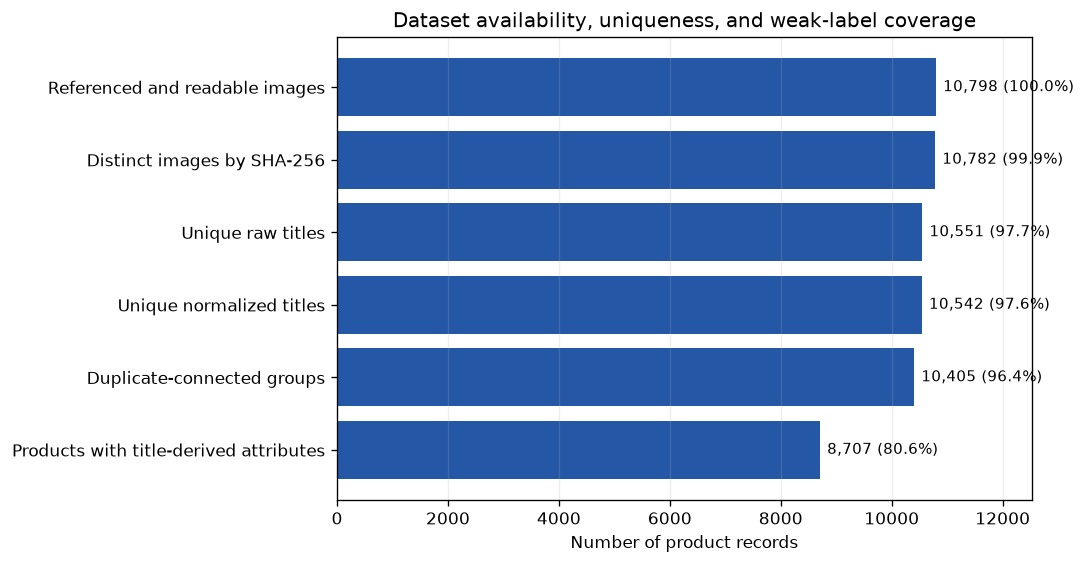

All 10,798 referenced images were readable.
10,782 distinct image contents remained after exact hashing.
8,707 products (80.64%) contained at least one lexicon-recognized attribute group.


In [3]:
summary = collections.OrderedDict([
    ('Referenced and readable images', sum(r['image_status'] == 'ok' for r in records)),
    ('Distinct images by SHA-256', len({r['image_sha256'] for r in records if r['image_sha256']})),
    ('Unique raw titles', len({r['title_raw'] for r in records})),
    ('Unique normalized titles', len({r['title_normalized'] for r in records})),
    ('Duplicate-connected groups', len({r['group_id'] for r in records})),
    ('Products with title-derived attributes', sum(bool(r['title_attributes']) for r in records)),
])
labels, values = list(summary.keys()), list(summary.values())
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(labels[::-1], values[::-1], color=COLORS['primary'])
annotate_bars(ax, values[::-1], denominator=N)
ax.set_xlim(0, N * 1.16)
ax.set_xlabel('Number of product records')
ax.set_title('Dataset availability, uniqueness, and weak-label coverage')
ax.grid(axis='x', alpha=.22)
save_figure(fig, 'figure_3_2_2_dataset_summary')

print(f'All {summary["Referenced and readable images"]:,} referenced images were readable.')
print(f'{summary["Distinct images by SHA-256"]:,} distinct image contents remained after exact hashing.')
print(f'{summary["Products with title-derived attributes"]:,} products '
      f'({100*summary["Products with title-derived attributes"]/N:.2f}%) contained at least one lexicon-recognized attribute group.')

## 3.2.3 Product-title characteristics

Title length is calculated after Unicode, case, punctuation, and whitespace normalization. A “word” here means a whitespace-separated token, not a linguistically segmented Vietnamese word.

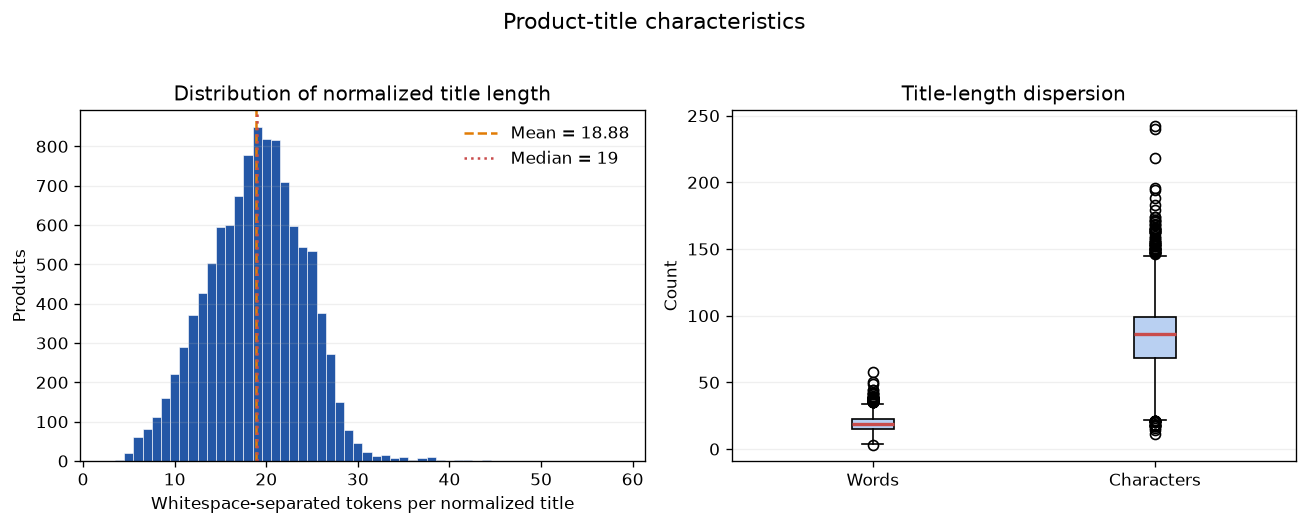

Title words — min/Q1/median/Q3/P90/P95/max: 3, 15, 19, 23, 25, 27, 58
Mean title length: 18.88 tokens; median character length: 86.
Interpretation: many titles contain more than a short product name, but longer titles may also include promotional or multi-variant text.


In [4]:
title_words = np.array([len(r['title_normalized'].split()) for r in records])
title_chars = np.array([len(r['title_normalized']) for r in records])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bins = np.arange(title_words.min(), title_words.max() + 2) - .5
axes[0].hist(title_words, bins=bins, color=COLORS['primary'], edgecolor='white', linewidth=.35)
axes[0].axvline(title_words.mean(), color=COLORS['accent'], linestyle='--',
                label=f'Mean = {title_words.mean():.2f}')
axes[0].axvline(np.median(title_words), color=COLORS['warning'], linestyle=':',
                label=f'Median = {np.median(title_words):.0f}')
axes[0].set(xlabel='Whitespace-separated tokens per normalized title', ylabel='Products',
            title='Distribution of normalized title length')
axes[0].legend(frameon=False)
axes[0].grid(axis='y', alpha=.2)
axes[1].boxplot([title_words, title_chars], tick_labels=['Words', 'Characters'],
                showfliers=True, patch_artist=True,
                boxprops={'facecolor': '#B9D0F2'}, medianprops={'color': COLORS['warning'], 'linewidth': 2})
axes[1].set_title('Title-length dispersion')
axes[1].set_ylabel('Count')
axes[1].grid(axis='y', alpha=.2)
fig.suptitle('Product-title characteristics', y=1.03, fontsize=13)
save_figure(fig, 'figure_3_2_3_title_characteristics')

q = np.percentile(title_words, [0, 25, 50, 75, 90, 95, 100])
print('Title words — min/Q1/median/Q3/P90/P95/max:', ', '.join(f'{x:.0f}' for x in q))
print(f'Mean title length: {title_words.mean():.2f} tokens; median character length: {np.median(title_chars):.0f}.')
print('Interpretation: many titles contain more than a short product name, but longer titles may also include promotional or multi-variant text.')

## 3.2.4 Image characteristics

The plot reports file dimensions only. It does not measure whether the image contains a single target garment, a collage, text overlays, or background products.

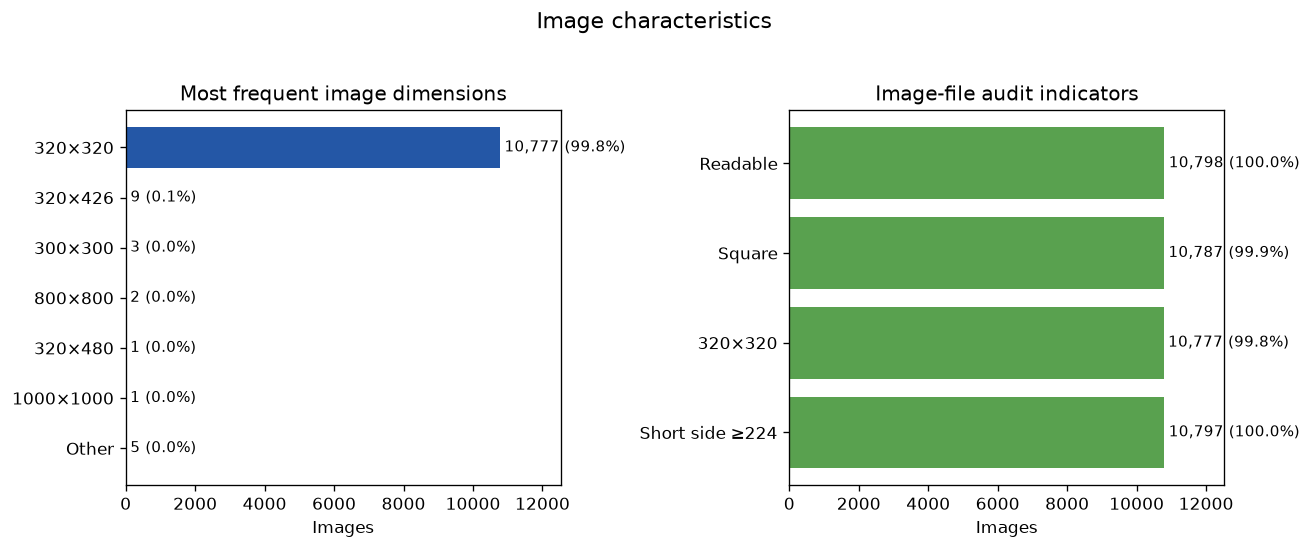

Median dimensions: 320×320 pixels.
10,777 images (99.81%) were 320×320 pixels.
Interpretation: image resolution is highly standardized, but visual-content quality requires separate manual annotation.


In [5]:
sizes = [tuple(r['image_size']) for r in records if r['image_size']]
size_counts = collections.Counter(sizes)
top_sizes = size_counts.most_common(6)
other = len(sizes) - sum(c for _, c in top_sizes)
size_labels = [f'{w}×{h}' for (w, h), _ in top_sizes] + (['Other'] if other else [])
size_values = [c for _, c in top_sizes] + ([other] if other else [])
square = sum(w == h for w, h in sizes)
short_224 = sum(min(w, h) < 224 for w, h in sizes)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].barh(size_labels[::-1], size_values[::-1], color=COLORS['primary'])
annotate_bars(axes[0], size_values[::-1], denominator=N)
axes[0].set_xlim(0, N * 1.16)
axes[0].set_xlabel('Images')
axes[0].set_title('Most frequent image dimensions')
facts = collections.OrderedDict([
    ('Readable', len(sizes)), ('Square', square),
    ('320×320', size_counts[(320, 320)]), ('Short side ≥224', len(sizes)-short_224)
])
axes[1].barh(list(facts.keys())[::-1], list(facts.values())[::-1], color=COLORS['secondary'])
annotate_bars(axes[1], list(facts.values())[::-1], denominator=N)
axes[1].set_xlim(0, N * 1.16)
axes[1].set_xlabel('Images')
axes[1].set_title('Image-file audit indicators')
fig.suptitle('Image characteristics', y=1.03, fontsize=13)
save_figure(fig, 'figure_3_2_4_image_characteristics')

widths, heights = zip(*sizes)
print(f'Median dimensions: {np.median(widths):.0f}×{np.median(heights):.0f} pixels.')
print(f'{size_counts[(320, 320)]:,} images ({100*size_counts[(320, 320)]/N:.2f}%) were 320×320 pixels.')
print('Interpretation: image resolution is highly standardized, but visual-content quality requires separate manual annotation.')

## 3.2.5 Title-inferred product composition

Categories below were assigned by ordered title rules. They describe the rule output in this sample and are neither manually verified categories nor platform-level market shares.

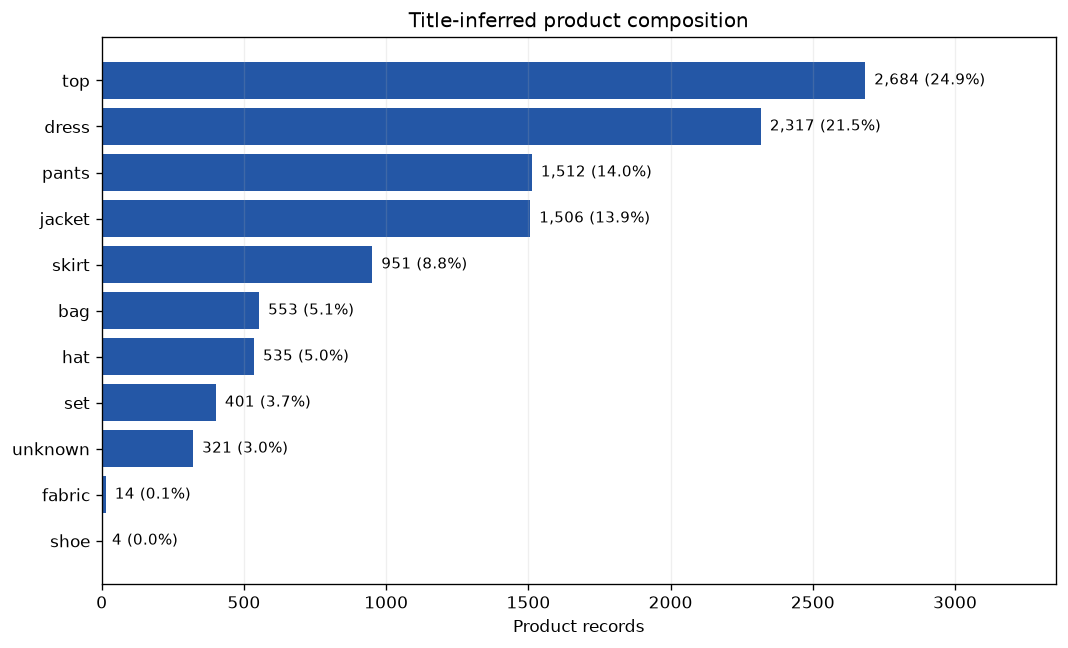

The five garment categories closest to the reference study contain 8,970 records (83.07%).
Interpretation: the sample also contains accessories, sets, fabric listings, and unknown records, so category-specific modeling is required.


In [6]:
category_counts = collections.Counter(r['category'] for r in records)
category_order = [k for k, _ in category_counts.most_common()]
category_values = [category_counts[k] for k in category_order]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(category_order[::-1], category_values[::-1], color=COLORS['primary'])
annotate_bars(ax, category_values[::-1], denominator=N)
ax.set_xlim(0, max(category_values) * 1.25)
ax.set_xlabel('Product records')
ax.set_title('Title-inferred product composition')
ax.grid(axis='x', alpha=.2)
save_figure(fig, 'figure_3_2_5_title_inferred_composition')

original_five = sum(category_counts[k] for k in ['top', 'dress', 'pants', 'jacket', 'skirt'])
print(f'The five garment categories closest to the reference study contain {original_five:,} records ({100*original_five/N:.2f}%).')
print('Interpretation: the sample also contains accessories, sets, fabric listings, and unknown records, so category-specific modeling is required.')

## 3.2.6 Coverage of title-derived weak attributes

Each bar counts products with at least one lexicon match in the corresponding group. Groups overlap because one product can mention several attributes. Material values remain seller claims rather than image-verified composition.

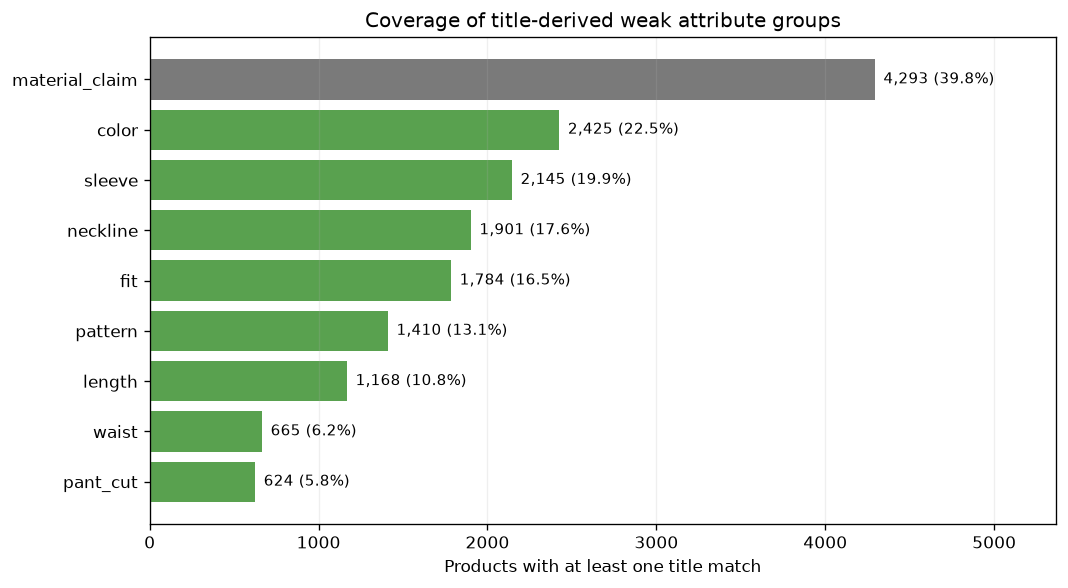

8,707 products (80.64%) contained at least one recognized attribute group.
The lexicon produced 17,687 canonical value mentions; group percentages overlap and must not be summed.


In [7]:
attribute_groups = collections.Counter(group for r in records for group in r['title_attributes'])
group_order = [k for k, _ in attribute_groups.most_common()]
group_values = [attribute_groups[k] for k in group_order]
fig, ax = plt.subplots(figsize=(9, 5))
colors = [COLORS['neutral'] if k == 'material_claim' else COLORS['secondary'] for k in group_order[::-1]]
ax.barh(group_order[::-1], group_values[::-1], color=colors)
annotate_bars(ax, group_values[::-1], denominator=N)
ax.set_xlim(0, max(group_values) * 1.25)
ax.set_xlabel('Products with at least one title match')
ax.set_title('Coverage of title-derived weak attribute groups')
ax.grid(axis='x', alpha=.2)
save_figure(fig, 'figure_3_2_6_weak_attribute_coverage')

total_mentions = sum(sum(len(v) for v in r['title_attributes'].values()) for r in records)
covered = sum(bool(r['title_attributes']) for r in records)
print(f'{covered:,} products ({100*covered/N:.2f}%) contained at least one recognized attribute group.')
print(f'The lexicon produced {total_mentions:,} canonical value mentions; group percentages overlap and must not be summed.')

## 3.2.7 Detected noise and ambiguity

Flags are non-exclusive audit indicators. Their total therefore exceeds the number of records carrying at least one flag.

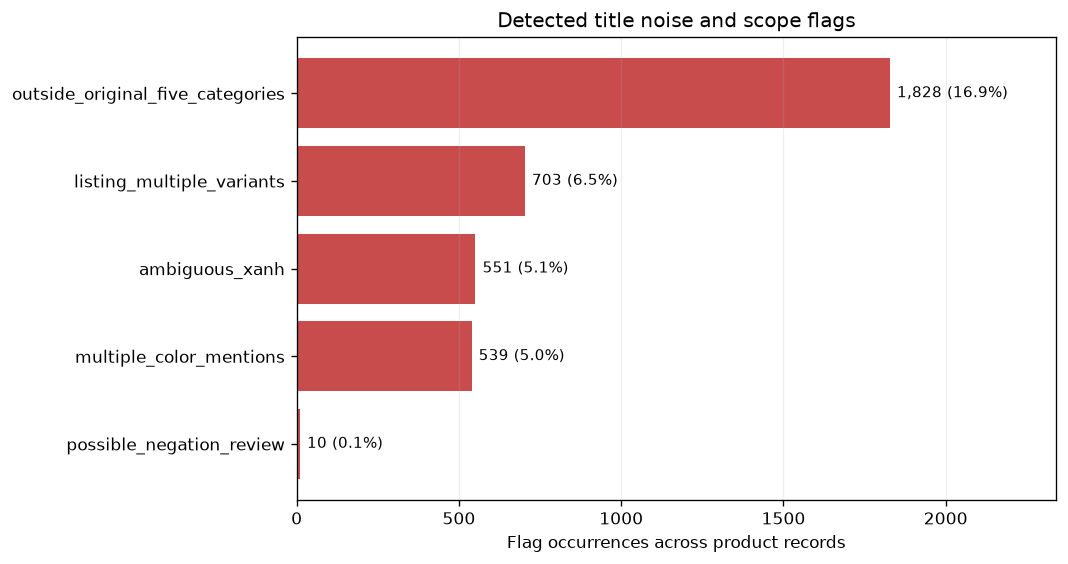

3,208 products (29.71%) received at least one audit flag.
Interpretation: the flags overlap and are conservative rule matches; they do not detect every noisy or mismatched listing.


In [8]:
flag_counts = collections.Counter(flag for r in records for flag in r['flags'])
flag_order = [k for k, _ in flag_counts.most_common()]
flag_values = [flag_counts[k] for k in flag_order]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(flag_order[::-1], flag_values[::-1], color=COLORS['warning'])
annotate_bars(ax, flag_values[::-1], denominator=N)
ax.set_xlim(0, max(flag_values) * 1.28)
ax.set_xlabel('Flag occurrences across product records')
ax.set_title('Detected title noise and scope flags')
ax.grid(axis='x', alpha=.2)
save_figure(fig, 'figure_3_2_7_noise_flags')

any_flag = sum(bool(r['flags']) for r in records)
print(f'{any_flag:,} products ({100*any_flag/N:.2f}%) received at least one audit flag.')
print('Interpretation: the flags overlap and are conservative rule matches; they do not detect every noisy or mismatched listing.')

## 3.2.8 Duplicate analysis and leakage control

The first panel reports the number of unique values under each duplicate indicator. The second expresses the corresponding reduction from the 10,798 records. Exact difference-hash equality is a heuristic and can produce collisions.

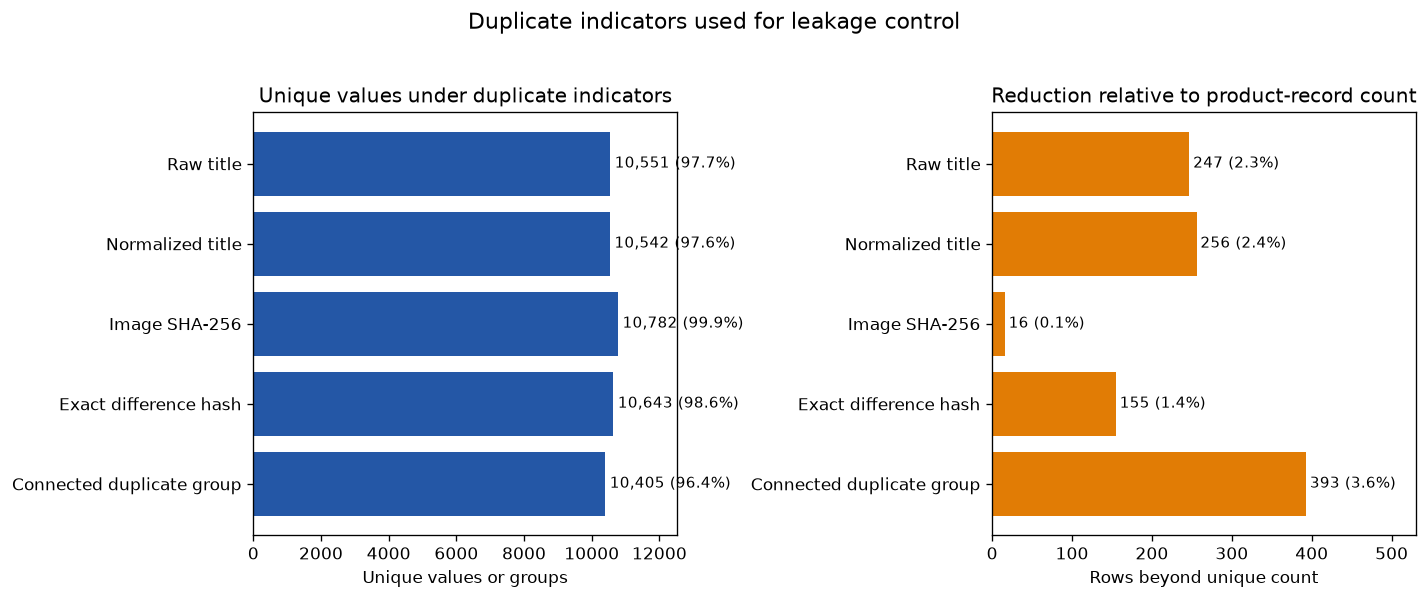

Connected duplicate groups: 10,405.
Detected groups crossing train/validation/test: 0.
Interpretation: the split controls identified duplicate groups, but does not prove removal of every near duplicate or seller-level dependency.


In [9]:
duplicate_summary = collections.OrderedDict([
    ('Raw title', len({r['title_raw'] for r in records})),
    ('Normalized title', len({r['title_normalized'] for r in records})),
    ('Image SHA-256', len({r['image_sha256'] for r in records if r['image_sha256']})),
    ('Exact difference hash', len({r['image_dhash'] for r in records if r['image_dhash']})),
    ('Connected duplicate group', len({r['group_id'] for r in records})),
])
labels = list(duplicate_summary.keys())
unique_values = list(duplicate_summary.values())
reductions = [N-v for v in unique_values]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].barh(labels[::-1], unique_values[::-1], color=COLORS['primary'])
annotate_bars(axes[0], unique_values[::-1], denominator=N)
axes[0].set_xlim(0, N * 1.16)
axes[0].set_xlabel('Unique values or groups')
axes[0].set_title('Unique values under duplicate indicators')
axes[1].barh(labels[::-1], reductions[::-1], color=COLORS['accent'])
annotate_bars(axes[1], reductions[::-1], denominator=N)
axes[1].set_xlim(0, max(reductions) * 1.35)
axes[1].set_xlabel('Rows beyond unique count')
axes[1].set_title('Reduction relative to product-record count')
fig.suptitle('Duplicate indicators used for leakage control', y=1.03, fontsize=13)
save_figure(fig, 'figure_3_2_8_duplicate_analysis')

cross_split = collections.defaultdict(set)
for r in records:
    cross_split[r['group_id']].add(r['split'])
leaking_groups = sum(len(splits) > 1 for splits in cross_split.values())
print(f'Connected duplicate groups: {duplicate_summary["Connected duplicate group"]:,}.')
print(f'Detected groups crossing train/validation/test: {leaking_groups}.')
print('Interpretation: the split controls identified duplicate groups, but does not prove removal of every near duplicate or seller-level dependency.')

## Combined numerical appendix and report notes

This final cell exports the numerical values behind the figures. Keep the following qualifications with the figures in the thesis:

1. Percentages characterize the analyzed collection only.
2. Title-inferred categories and attributes are weak, rule-derived labels.
3. Attribute-group and audit-flag counts overlap.
4. Image dimensions do not measure semantic image quality.
5. Duplicate indicators reduce leakage risk but do not prove that all near duplicates were removed.

In [10]:
tables = {
    '3_2_2_dataset_summary': summary,
    '3_2_5_title_inferred_categories': category_counts,
    '3_2_6_weak_attribute_groups': attribute_groups,
    '3_2_7_noise_flags': flag_counts,
    '3_2_8_duplicate_unique_counts': duplicate_summary,
}
for stem, mapping in tables.items():
    with (FIGURE_DIR / f'{stem}.csv').open('w', encoding='utf-8-sig', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['indicator', 'count', 'percentage_of_records'])
        for key, value in mapping.items():
            writer.writerow([key, value, 100 * value / N])

print('Exported figures:')
for path in sorted(FIGURE_DIR.glob('figure_*')):
    print(' -', path.relative_to(PROJECT_ROOT))
print('\nExported supporting CSV tables:')
for path in sorted(FIGURE_DIR.glob('*.csv')):
    print(' -', path.relative_to(PROJECT_ROOT))

Exported figures:
 - outputs\figures\dataset_audit\figure_3_2_2_dataset_summary.png
 - outputs\figures\dataset_audit\figure_3_2_2_dataset_summary.svg
 - outputs\figures\dataset_audit\figure_3_2_3_title_characteristics.png
 - outputs\figures\dataset_audit\figure_3_2_3_title_characteristics.svg
 - outputs\figures\dataset_audit\figure_3_2_4_image_characteristics.png
 - outputs\figures\dataset_audit\figure_3_2_4_image_characteristics.svg
 - outputs\figures\dataset_audit\figure_3_2_5_title_inferred_composition.png
 - outputs\figures\dataset_audit\figure_3_2_5_title_inferred_composition.svg
 - outputs\figures\dataset_audit\figure_3_2_6_weak_attribute_coverage.png
 - outputs\figures\dataset_audit\figure_3_2_6_weak_attribute_coverage.svg
 - outputs\figures\dataset_audit\figure_3_2_7_noise_flags.png
 - outputs\figures\dataset_audit\figure_3_2_7_noise_flags.svg
 - outputs\figures\dataset_audit\figure_3_2_8_duplicate_analysis.png
 - outputs\figures\dataset_audit\figure_3_2_8_duplicate_analysis.sv